# PRACTICE 3 — GET STARTED WITH HUGGING FACE

**Học phần:** Deep Learning · **Nhóm:** 4  
**Dữ liệu:** IMDb, phân loại review thành `NEGATIVE (0)` và `POSITIVE (1)`.

### Cấu trúc notebook

- **Phần A — Chuẩn bị và EDA/PCA:** Xác định dữ liệu, thống kê, trực quan hóa và xem xét độ dài chuỗi.
- **Phần B — Exercise 1:** Tokenize câu và suy luận bằng mô hình sentiment pretrained từ Hugging Face Hub.
- **Phần C — Exercise 2:** Tải IMDb → chia train/validation/test → tokenization → fine-tune DistilBERT bằng `Trainer` → chọn checkpoint → đánh giá test → lưu kết quả → dự đoán câu mới.
- **Phần D — Kiểm chứng và tổng kết:** Kiểm tra kết quả thực nghiệm đã lưu, phân biệt kết quả cũ và lần chạy mới.

**Quy tắc thực nghiệm:** Chỉ sử dụng validation để lựa chọn checkpoint; test dùng một lần sau khi hoàn tất huấn luyện. EDA/PCA chỉ khảo sát `train` gốc, không đưa PCA vào DistilBERT.

> Các cell có output trong file bàn giao được chạy ở chế độ **kiểm chứng ngoại tuyến** trên dữ liệu/kết quả đã lưu. Cell cần Hugging Face Hub và fine-tuning phải chạy trên máy có mạng và thư viện phù hợp. Notebook không tự gán kết quả 89% cũ cho pipeline mới.

## Phần A.1 — Chuẩn bị môi trường và thư mục dự án

Cài thư viện trong **terminal** ở thư mục Lab 3: `python -m pip install -r requirements.txt`. Trong Jupyter có thể chạy `%pip install -r requirements.txt` tại một cell riêng khi cần. Chọn đúng Python Kernel ở góc phải VS Code, sau khi cài hãy Restart Kernel.

**Chế độ chạy:** Mặc định `RUN_HF=True` và `RUN_TRAIN=True` khi mở notebook bình thường, nghĩa là chạy đầy đủ cả hai bài với mạng Internet. Trước khi chạy toàn bộ, kiểm tra tài nguyên máy vì fine-tuning có thể tốn nhiều thời gian. Có thể đặt `RUN_TRAIN=False` trong cell dưới để chỉ kiểm tra các bước trước huấn luyện.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import os, sys, json, platform, importlib.util

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Tìm thư mục gốc để notebook chạy được ở root hoặc trong notebooks/.
project_root = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / 'configs' / 'default.json').exists()), None)
if project_root is None:
    raise FileNotFoundError('Mở notebook trong thư mục Lab3_DL_Group4-main (chứa configs/default.json).')
os.chdir(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.utils import read_config, save_json
config = read_config(project_root / 'configs/default.json')
RESULT_DIR = project_root / 'outputs' / 'notebook_full'
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# Cờ này chỉ dùng khi kiểm thử ngoại tuyến; chế độ bình thường là chạy thực nghiệm Hugging Face.
OFFLINE_VERIFY = os.getenv('LAB3_OFFLINE_VERIFY', '0') == '1'
RUN_HF = not OFFLINE_VERIFY
RUN_TRAIN = not OFFLINE_VERIFY

print('Thư mục project:', project_root)
print('Python:', sys.version.split()[0], '| Hệ điều hành:', platform.system())
print('RUN_HF =', RUN_HF, '| RUN_TRAIN =', RUN_TRAIN)
print('Cấu hình:', json.dumps(config, ensure_ascii=False))

Thư mục project: /mnt/data/lab3_work/Lab3_DL_Group4-main
Python: 3.13.5 | Hệ điều hành: Linux
RUN_HF = False | RUN_TRAIN = False
Cấu hình: {"seed": 42, "dataset": "stanfordnlp/imdb", "model": "distilbert/distilbert-base-uncased", "train_size": 1000, "validation_size": 200, "test_size": 200, "max_length": 256, "epochs": 2, "batch_size": 8, "learning_rate": 2e-05, "weight_decay": 0.01, "selection_metric": "eval_loss"}


## Phần A.2 — Kiểm tra thư viện và cấu hình thí nghiệm

- `transformers`: mô hình pretrained, tokenizer, `Trainer`.
- `datasets`: tải và chia IMDb.
- `evaluate`: thư viện đánh giá của Hugging Face; các metric chính trong project được tính bằng `scikit-learn`.
- `accelerate`: backend cần thiết cho `Trainer`.
- `torch`: tensor, suy luận và cập nhật trọng số.

Dùng `seed=42` để cố định những thao tác ngẫu nhiên trong lấy mẫu và huấn luyện ở mức có thể; kết quả còn phụ thuộc phần cứng và phiên bản thư viện.

In [2]:
modules = ['torch', 'transformers', 'datasets', 'evaluate', 'accelerate',
           'sklearn', 'pandas', 'numpy', 'matplotlib']
for name in modules:
    print(f'{name:14s}:', 'Đã cài' if importlib.util.find_spec(name) else 'Chưa cài')

print('Tập train/validation/test dự kiến:',
      config['train_size'], config['validation_size'], config['test_size'])
print('Model fine-tune:', config['model'])
print('Tiêu chí chọn checkpoint:', config['selection_metric'])

if RUN_HF:
    missing = [m for m in ['torch', 'transformers', 'datasets', 'accelerate', 'evaluate']
               if importlib.util.find_spec(m) is None]
    if missing:
        raise ModuleNotFoundError('Thiếu thư viện: ' + ', '.join(missing)
                                  + '. Hãy chạy python -m pip install -r requirements.txt')

torch         : Đã cài
transformers  : Chưa cài
datasets      : Chưa cài
evaluate      : Chưa cài
accelerate    : Chưa cài
sklearn       : Đã cài
pandas        : Đã cài
numpy         : Đã cài
matplotlib    : Đã cài
Tập train/validation/test dự kiến: 1000 200 200
Model fine-tune: distilbert/distilbert-base-uncased
Tiêu chí chọn checkpoint: eval_loss


## Phần A.3 — Nạp IMDb và kiểm tra dữ liệu đầu vào

`stanfordnlp/imdb` có hai split chuẩn: `train` và `test`. Tập `train` gốc dùng cho khảo sát EDA và lấy train/validation; tập `test` gốc dành cho kiểm tra cuối. Mỗi bản ghi có `text` và `label`.

Ở chế độ ngoại tuyến, cell sử dụng **bảng tổng hợp đã lưu từ lần EDA trước**, không giả lập việc tải dataset mới.

In [3]:
raw = None
raw_train_df = None

if RUN_HF:
    from datasets import load_dataset
    raw = load_dataset(config['dataset'])
    print(raw)
    raw_train_df = raw['train'].to_pandas()[['text', 'label']].copy()
    raw_train_df['label_name'] = raw_train_df['label'].map({0:'NEGATIVE', 1:'POSITIVE'})
    raw_train_df['length_words'] = raw_train_df['text'].fillna('').str.split().str.len()
    print('Train gốc:', len(raw['train']), '| Test gốc:', len(raw['test']))
    display(raw_train_df[['label_name','length_words']].head())
else:
    old_eda = pd.read_csv(project_root / 'eda_summary_by_class.csv')
    print('CHẾ ĐỘ NGOẠI TUYẾN: chỉ đọc eda_summary_by_class.csv đã lưu, không tải IMDb.')
    display(old_eda)

CHẾ ĐỘ NGOẠI TUYẾN: chỉ đọc eda_summary_by_class.csv đã lưu, không tải IMDb.


,label,samples,mean_words,median_words,mean_characters,missing_text,duplicate_texts
0,NEGATIVE,12500,228.48728,173.0,1279.51040,0,68
1,POSITIVE,12500,234.48600,172.0,1325.21536,0,28


## Phần A.4 — EDA: chất lượng và phân phối nhãn

Kiểm tra: dữ liệu thiếu, review rỗng, văn bản trùng, trường hợp **cùng văn bản nhưng có nhãn mâu thuẫn**, thống kê số từ. Việc tìm review trùng giúp nhận diện rủi ro chất lượng dữ liệu; chưa tự động xóa tất cả bản ghi trùng vì cần giữ khả năng đối chiếu với thí nghiệm trước.

In [4]:
if RUN_HF:
    df = raw_train_df
    missing = int(df['text'].isna().sum())
    empty = int(df['text'].fillna('').str.strip().eq('').sum())
    duplicates = int(df['text'].duplicated().sum())
    conflict_groups = df.groupby('text')['label'].nunique()
    conflicts = int((conflict_groups > 1).sum())
    stats = df.groupby('label_name')['length_words'].agg(['count','mean','median','min','max'])
    print('Missing:',missing,'| Empty:',empty,'| Duplicates:',duplicates,
          '| Nhóm văn bản trùng khác nhãn:',conflicts)
    display(stats.round(2))
    stats.to_csv(RESULT_DIR / 'eda_length_by_label.csv')
    save_json(RESULT_DIR / 'eda_quality.json',
              {'dataset': config['dataset'], 'split':'train', 'size':len(df),
               'missing':missing,'empty':empty,'duplicate_texts':duplicates,
               'conflicting_text_groups':conflicts})
else:
    print('Số liệu lưu từ EDA gốc: 25.000 review train; mỗi nhãn 12.500; 96 văn bản trùng.')
    print('Chưa chạy kiểm tra nhóm văn bản trùng khác nhãn trong notebook mới (cần tải IMDb).')

Số liệu lưu từ EDA gốc: 25.000 review train; mỗi nhãn 12.500; 96 văn bản trùng.
Chưa chạy kiểm tra nhóm văn bản trùng khác nhãn trong notebook mới (cần tải IMDb).


## Phần A.5 — Biểu đồ phân phối nhãn và độ dài review

Phân bố nhãn cân bằng hỗ trợ huấn luyện bộ phân loại nhị phân. Biểu đồ độ dài phục vụ lựa chọn `max_length=256` — review dài hơn giới hạn token sẽ bị cắt ở bước tokenization.

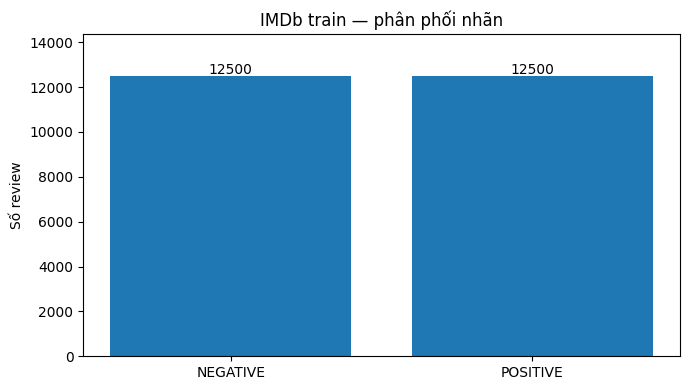

Biểu đồ độ dài đã xuất từ lần EDA trước: review_length_distribution.png


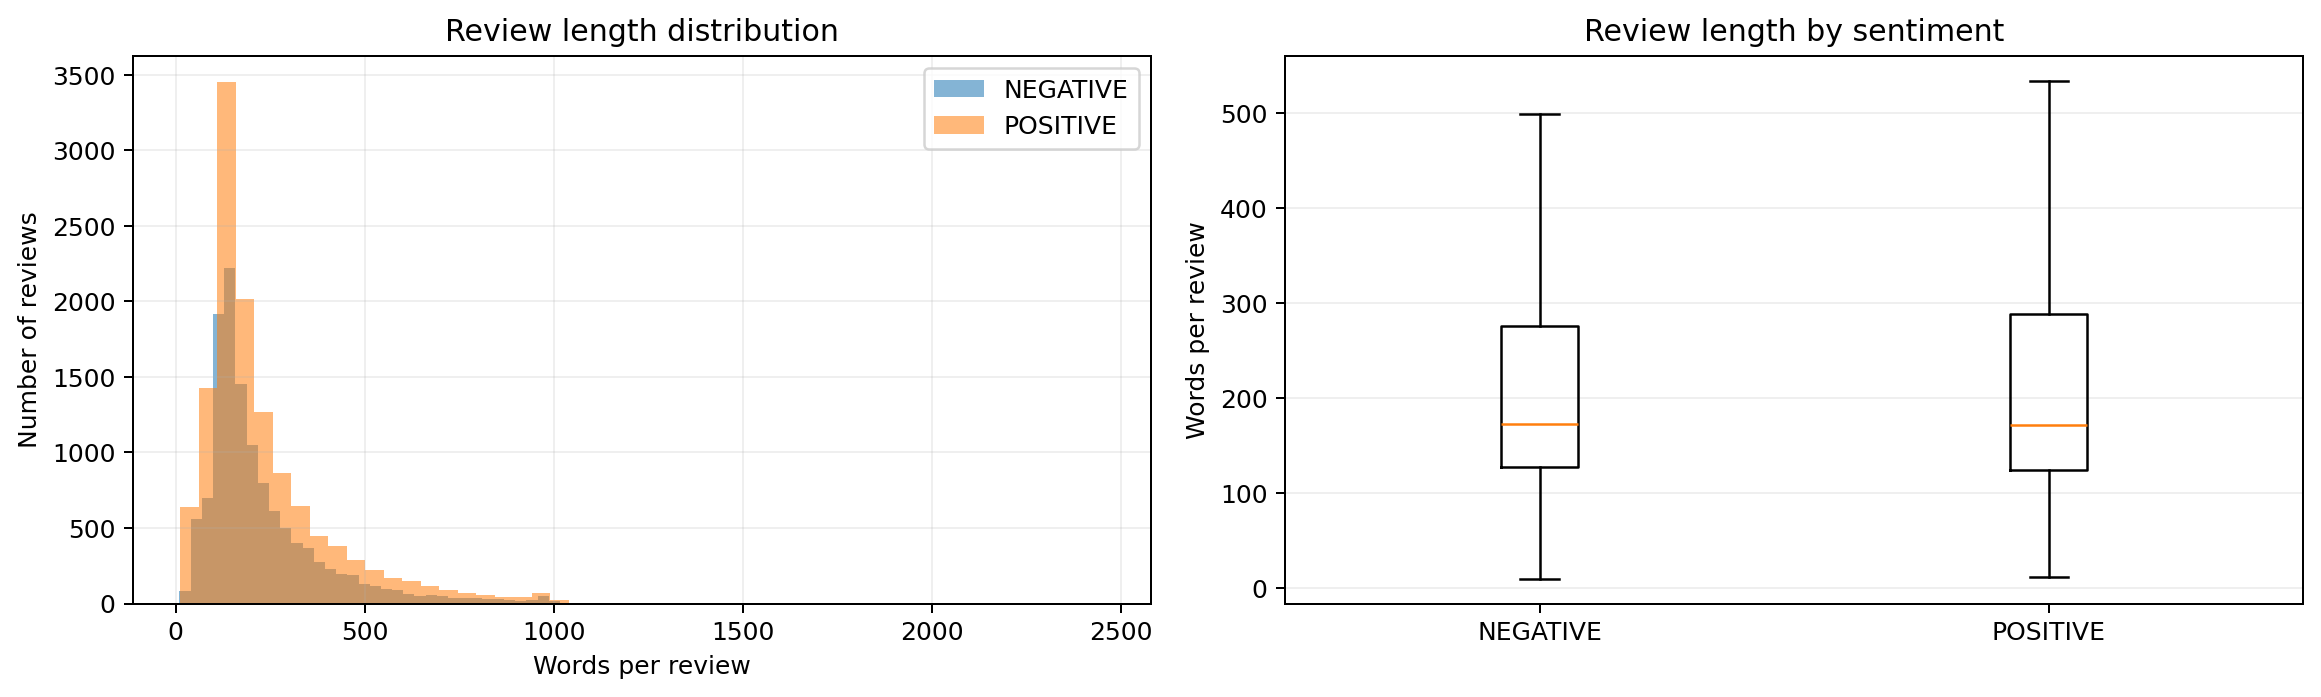

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
if RUN_HF:
    counts = raw_train_df['label_name'].value_counts().reindex(['NEGATIVE','POSITIVE'])
else:
    counts = pd.Series(dict(zip(old_eda['label'], old_eda['samples'])))
    counts = counts.reindex(['NEGATIVE','POSITIVE'])
ax.bar(counts.index, counts.values)
for i, value in enumerate(counts.values):
    ax.text(i, value + 100, str(int(value)), ha='center')
ax.set(title='IMDb train — phân phối nhãn', ylabel='Số review', ylim=(0, max(counts.values)*1.15))
plt.tight_layout()
plt.show()

if RUN_HF:
    fig, ax = plt.subplots(figsize=(9, 4))
    for label in ['NEGATIVE','POSITIVE']:
        vals = raw_train_df.loc[raw_train_df['label_name'].eq(label),'length_words']
        ax.hist(vals, bins=45, alpha=.5, label=label)
    ax.set(xlabel='Số từ trong review',ylabel='Số lượng',title='Độ dài review IMDb train')
    ax.legend(); plt.tight_layout()
    fig.savefig(RESULT_DIR / 'eda_review_lengths.png', dpi=160)
    plt.show()
else:
    print('Biểu đồ độ dài đã xuất từ lần EDA trước: review_length_distribution.png')
    display(Image(filename=str(project_root / 'review_length_distribution.png'), width=750))

## Phần A.6 — PCA trên đặc trưng TF-IDF

PCA chỉ dùng để **khảo sát** dữ liệu văn bản trước khi fine-tune. Quy trình: chọn 500 review mỗi lớp từ split `train` → TF-IDF 1.000 đặc trưng → chuyển ma trận dense → PCA 2 thành phần → biểu đồ 2D và explained variance.

PCA ở đây không áp dụng lên embedding của Transformer và **không được đưa vào pipeline DistilBERT**. Hai thành phần PCA chỉ giữ một phần phương sai, vì vậy không kết luận độ chính xác phân loại từ mức tách biệt của hình 2D.

Đang đọc tọa độ PCA từ pca_coordinates.csv (kết quả đã lưu trước đây).
Số điểm: 1000 | PC1 = 0.978 % | PC2 = 0.714 % | Tổng = 1.692 %


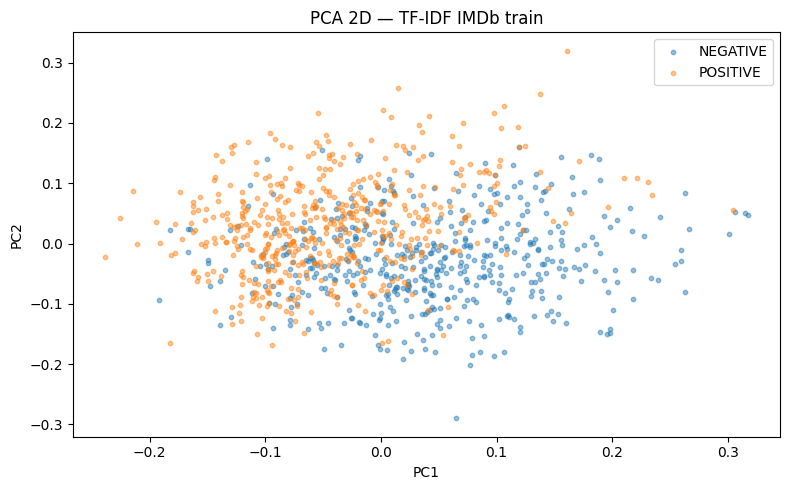

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA

if RUN_HF:
    pca_sample = (raw_train_df.groupby('label', group_keys=False)
        .sample(n=500, random_state=config['seed'])
        .sample(frac=1, random_state=config['seed']).reset_index(drop=True))
    vectorizer = TfidfVectorizer(max_features=1000, min_df=3, max_df=.95,
                                 stop_words='english', sublinear_tf=True)
    X = vectorizer.fit_transform(pca_sample['text'].fillna('')).toarray()
    pca = PCA(n_components=2, svd_solver='randomized', random_state=config['seed'])
    Z = pca.fit_transform(X)
    coords = pd.DataFrame({'PC1':Z[:,0], 'PC2':Z[:,1],
                           'label':pca_sample['label'].values,
                           'label_name':pca_sample['label_name'].values})
    variance = list(map(float,pca.explained_variance_ratio_))
    coords.to_csv(RESULT_DIR/'pca_coordinates.csv',index=False)
    save_json(RESULT_DIR/'pca_metadata.json',
              {'source':'IMDb train','samples':len(coords),'features':X.shape[1],
               'explained_variance_ratio':variance,
               'cumulative_variance':sum(variance)})
else:
    coords = pd.read_csv(project_root/'pca_coordinates.csv')
    pca_info = json.loads((project_root/'pca_metadata.json').read_text(encoding='utf-8'))
    variance = pca_info['explained_variance_ratio']
    print('Đang đọc tọa độ PCA từ pca_coordinates.csv (kết quả đã lưu trước đây).')

print('Số điểm:',len(coords),'| PC1 =',round(variance[0]*100,3),'%',
      '| PC2 =',round(variance[1]*100,3),'%',
      '| Tổng =',round(sum(variance)*100,3),'%')
fig, ax = plt.subplots(figsize=(8, 5))
for name in ['NEGATIVE','POSITIVE']:
    part = coords.loc[coords['label_name'].eq(name)]
    ax.scatter(part['PC1'],part['PC2'],s=10,alpha=.45,label=name)
ax.set(title='PCA 2D — TF-IDF IMDb train',xlabel='PC1',ylabel='PC2')
ax.legend();plt.tight_layout()
if RUN_HF:
    fig.savefig(RESULT_DIR/'pca_visualization.png',dpi=160)
plt.show()

## Phần B — Exercise 1: Sentiment Analysis with Hugging Face

**Theo đề:** (1) cài `transformers`; (2) dùng sentiment model pretrained từ Hub; (3) tokenize một câu; (4) dự đoán sentiment của câu.

Exercise 1 **không có bước train**. Sử dụng checkpoint `distilbert/distilbert-base-uncased-finetuned-sst-2-english` đã được fine-tune để suy luận trực tiếp. Không nhầm checkpoint này với `distilbert-base-uncased` dùng khởi tạo Exercise 2.

### B.1 — Tải pretrained sentiment model và tokenizer

`AutoTokenizer` mã hóa câu thành token IDs. `AutoModelForSequenceClassification` có classification head nhị phân từ checkpoint SST-2, không phải mô hình từ lần train IMDb của nhóm.

In [7]:
ex1_tokenizer = ex1_model = ex1_device = None
EX1_CHECKPOINT = 'distilbert/distilbert-base-uncased-finetuned-sst-2-english'
if RUN_HF:
    import torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    ex1_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    ex1_tokenizer = AutoTokenizer.from_pretrained(EX1_CHECKPOINT)
    ex1_model = AutoModelForSequenceClassification.from_pretrained(EX1_CHECKPOINT).to(ex1_device)
    ex1_model.eval()
    print('Đã tải:', EX1_CHECKPOINT, '| Thiết bị:', ex1_device)
else:
    print('EX1 chưa được suy luận trong lượt kiểm thử ngoại tuyến (không có pretrained weights).')

EX1 chưa được suy luận trong lượt kiểm thử ngoại tuyến (không có pretrained weights).


### B.2 — Tokenize câu mẫu

Khi chạy online sẽ in `tokens`, `input_ids`, `attention_mask` và shape tensor. `attention_mask=1` chỉ token có nội dung, `0` biểu thị vị trí padding (nếu có).

In [8]:
SAMPLE_SENTENCE = 'I love this movie. The acting is amazing!'
if RUN_HF:
    encoded_ex1 = ex1_tokenizer(SAMPLE_SENTENCE, return_tensors='pt',
                                truncation=True, max_length=512)
    print('Câu mẫu:', SAMPLE_SENTENCE)
    print('Tokens:',ex1_tokenizer.convert_ids_to_tokens(encoded_ex1['input_ids'][0]))
    print('input_ids:',encoded_ex1['input_ids'][0].tolist())
    print('attention_mask:',encoded_ex1['attention_mask'][0].tolist())
    print('Tensor shape:', tuple(encoded_ex1['input_ids'].shape))
else:
    print('Chưa tokenize bằng pretrained tokenizer; chạy online để có input_ids thực tế.')

Chưa tokenize bằng pretrained tokenizer; chạy online để có input_ids thực tế.


### B.3 — Dự đoán cảm xúc câu mẫu và so sánh ví dụ

`model(**inputs).logits` tạo điểm chưa chuẩn hóa; `softmax` biến logits thành xác suất. Lấy `argmax` để chọn nhãn dự đoán. Điểm softmax không nên xem là độ chắc chắn đã được hiệu chuẩn.

In [9]:
example_texts = [
    SAMPLE_SENTENCE,
    'This is a terrible film, boring from start to finish.',
    'Some parts were good, but the ending was disappointing.'
]
if RUN_HF:
    ex1_inputs = ex1_tokenizer(example_texts, padding=True, truncation=True,
                               max_length=512, return_tensors='pt').to(ex1_device)
    with torch.no_grad():
        ex1_probs = torch.softmax(ex1_model(**ex1_inputs).logits,dim=-1).cpu().numpy()
    ex1_ids = ex1_probs.argmax(axis=1)
    ex1_table = pd.DataFrame({
        'text':example_texts,
        'predicted_label':[ex1_model.config.id2label[int(i)] for i in ex1_ids],
        'score':[float(ex1_probs[k,i]) for k,i in enumerate(ex1_ids)]})
    display(ex1_table)
    ex1_table.to_csv(RESULT_DIR/'exercise1_predictions.csv',index=False)
else:
    print('EX1 chưa dự đoán trong lượt kiểm thử ngoại tuyến; chỉ hiển thị nhãn và score khi chạy trực tiếp pretrained model.')

EX1 chưa dự đoán trong lượt kiểm thử ngoại tuyến; chỉ hiển thị nhãn và score khi chạy trực tiếp pretrained model.


## Phần C — Exercise 2: Fine-tuning Pretrained Model for Binary Text Classification

**Các bước theo đề:** cài thư viện → tải IMDb nhị phân → tải model và tokenizer → tiền xử lý → `TrainingArguments` → `Trainer` + fine-tuning → đánh giá.

Khác Exercise 1, bài này dùng `distilbert/distilbert-base-uncased` làm trọng số khởi tạo, thêm classification head 2 lớp rồi cập nhật trọng số theo nhãn IMDb. Lớp phân loại mới có thể khởi tạo ngẫu nhiên, đây là hành vi bình thường.

### C.1 — Tách train, validation, test và kiểm tra không chồng lấn

Tập `train` gốc được phân tầng (stratified) thành nguồn lấy mẫu train/validation; test chỉ lấy từ split `test` riêng. Cấu hình mặc định: train 1.000, validation 200, test 200. **Lưu ý:** test 200 mẫu lấy ngẫu nhiên nên không bắt buộc cân bằng tuyệt đối. Hãy xem phân phối nhãn thực tế khi chạy.

In [10]:
train_set = val_set = test_set = None
if RUN_HF:
    from transformers import set_seed
    from src.data import prepare_splits
    set_seed(config['seed'])
    train_set, val_set, test_set = prepare_splits(config)
    summary = {name:{'size':len(ds),'labels':dict(Counter(ds['label']))}
               for name, ds in [('train',train_set),('validation',val_set),('test',test_set)]}
    save_json(RESULT_DIR/'data_summary.json',summary)
    display(pd.DataFrame([{'split':name,**details} for name,details in summary.items()]))
    print('Không có text trùng giữa train và validation:',
          set(train_set['text']).isdisjoint(val_set['text']))
else:
    print('Không tải IMDb trong chế độ ngoại tuyến; cấu hình dự kiến:',
          config['train_size'],config['validation_size'],config['test_size'])
    print('Không suy diễn đây là số lượng thực tế của một lần chạy mới.')

Không tải IMDb trong chế độ ngoại tuyến; cấu hình dự kiến: 1000 200 200
Không suy diễn đây là số lượng thực tế của một lần chạy mới.


### C.2 — Khởi tạo tokenizer và model DistilBERT

`AutoTokenizer.from_pretrained` sử dụng tokenizer của mô hình. `AutoModelForSequenceClassification` tạo đầu ra 2 lớp. `id2label/label2id` đảm bảo nhãn tương ứng khi lưu và tải lại checkpoint.

In [11]:
ex2_tokenizer = ex2_model = None
if RUN_HF:
    from src.model import load_model_and_tokenizer
    ex2_tokenizer, ex2_model = load_model_and_tokenizer(config['model'])
    print('Model:',ex2_model.config.model_type,
          '| Số nhãn:',ex2_model.config.num_labels,
          '| Tham số:',format(sum(p.numel() for p in ex2_model.parameters()),','))
    print('Ánh xạ nhãn:',ex2_model.config.id2label)
else:
    print('EX2 chưa tải DistilBERT; cần tải mô hình để thống kê tham số.')

EX2 chưa tải DistilBERT; cần tải mô hình để thống kê tham số.


### C.3 — Tokenization và Data Collator

- `truncation=True` và `max_length=256` giới hạn số token đầu vào để kiểm soát bộ nhớ.
- `DataCollatorWithPadding` chỉ padding động theo độ dài lớn nhất trong mỗi batch, giảm padding dư.
- Các cột `text` có thể còn trong `Dataset`; `Trainer` sẽ loại bỏ cột không phải đầu vào của mô hình trong lúc tạo batch.

In [12]:
train_tok = val_tok = test_tok = collator = None
if RUN_HF:
    from transformers import DataCollatorWithPadding
    def tokenize_batch(batch):
        return ex2_tokenizer(batch['text'],truncation=True,
                             max_length=config['max_length'])
    train_tok = train_set.map(tokenize_batch,batched=True,desc='Tokenize train')
    val_tok = val_set.map(tokenize_batch,batched=True,desc='Tokenize validation')
    test_tok = test_set.map(tokenize_batch,batched=True,desc='Tokenize test')
    collator = DataCollatorWithPadding(tokenizer=ex2_tokenizer)
    lengths = [len(x) for x in train_tok['input_ids']]
    print('Ví dụ token IDs:',train_tok[0]['input_ids'][:25])
    print('Ví dụ attention mask:',train_tok[0]['attention_mask'][:25])
    print('Chiều dài token: mean =',round(float(np.mean(lengths)),2),
          '| max =',max(lengths))
else:
    print('Chưa tokenization IMDb mới trong chế độ ngoại tuyến.')

Chưa tokenization IMDb mới trong chế độ ngoại tuyến.


### C.4 — Khai báo TrainingArguments

Với phân loại nhị phân, mô hình tối ưu cross-entropy. Sử dụng AdamW, learning rate `2e-5`, weight decay `0.01`, batch size `8` và `2` epoch từ `configs/default.json`. Đánh giá và lưu mỗi epoch, **lấy best checkpoint theo `eval_loss` thấp nhất**. Tiêu chí này nhất quán với `load_best_model_at_end=True`.

In [13]:
training_args = None
if RUN_HF:
    from transformers import TrainingArguments
    training_args = TrainingArguments(
        output_dir=str(RESULT_DIR / 'checkpoints'),
        seed=config['seed'], data_seed=config['seed'],
        num_train_epochs=config['epochs'],
        per_device_train_batch_size=config['batch_size'],
        per_device_eval_batch_size=config['batch_size'],
        learning_rate=config['learning_rate'],
        weight_decay=config['weight_decay'],
        eval_strategy='epoch',save_strategy='epoch',logging_strategy='epoch',
        load_best_model_at_end=True,
        metric_for_best_model='eval_loss', greater_is_better=False,
        save_total_limit=2, report_to='none', optim='adamw_torch',
    )
    print('Thiết bị:',training_args.device)
    print('Epochs:',training_args.num_train_epochs,
          '| Batch:',training_args.per_device_train_batch_size,
          '| LR:',training_args.learning_rate)
else:
    print('TrainingArguments được định nghĩa trong cell; chưa khởi tạo vì chưa tải thư viện Hugging Face.')

TrainingArguments được định nghĩa trong cell; chưa khởi tạo vì chưa tải thư viện Hugging Face.


### C.5 — Trainer và fine-tuning

`Trainer` điều phối forward pass, tính loss, backward pass, cập nhật weights và đánh giá validation. `compute_metrics` lấy từ **`src.evaluate`** (đã sửa lỗi import của notebook cũ). Khi `RUN_TRAIN=True`, cell này sẽ cập nhật trọng số và lưu checkpoint. Không sử dụng test để quyết định dừng/chọn checkpoint.

In [14]:
trainer = None
train_result = None
training_started = None
if RUN_HF:
    from transformers import Trainer
    from src.evaluate import compute_metrics
    trainer = Trainer(
        model=ex2_model,
        args=training_args,
        train_dataset=train_tok,
        eval_dataset=val_tok,
        processing_class=ex2_tokenizer,
        data_collator=collator,
        compute_metrics=compute_metrics,
    )
    if RUN_TRAIN:
        training_started = datetime.now(timezone.utc).isoformat()
        train_result = trainer.train()
        trainer.save_state()
        print('Đã huấn luyện. Training loss cuối:',float(train_result.training_loss))
        print('Checkpoint chọn theo eval_loss:',trainer.state.best_model_checkpoint)
        print('Best validation loss:',trainer.state.best_metric)
    else:
        print('RUN_TRAIN=False: tạo Trainer thành công nhưng chưa huấn luyện.')
else:
    print('Chưa tạo Trainer trong lần kiểm thử ngoại tuyến, chưa train DistilBERT.')

Chưa tạo Trainer trong lần kiểm thử ngoại tuyến, chưa train DistilBERT.


### C.6 — Lưu lịch sử và biểu đồ training/validation loss

`trainer.state.log_history` lưu các bản ghi theo epoch. Bảng `history.csv` và hình `loss_curves.png` cho phép theo dõi hiện tượng overfitting. Khi validation loss tăng trong lúc train loss giảm, cần xem xét điều chỉnh epoch, regularization hoặc early stopping.

In [15]:
if RUN_HF and RUN_TRAIN and trainer is not None:
    from src.visualize import save_training_history
    save_training_history(trainer.state.log_history, RESULT_DIR)
    history = pd.read_csv(RESULT_DIR/'history.csv')
    display(history.tail(12))
    display(Image(filename=str(RESULT_DIR/'loss_curves.png'),width=750))
else:
    print('Chưa có history.csv mới vì fine-tuning chưa được thực thi.')

Chưa có history.csv mới vì fine-tuning chưa được thực thi.


### C.7 — Đánh giá trên test và xuất kết quả

Sau khi `Trainer` nạp checkpoint tốt nhất theo validation loss, dự đoán toàn bộ test đã chọn. Xuất accuracy, precision/recall/F1 của lớp Positive, confusion matrix, classification report và dự đoán theo từng review. Tập test không tham gia huấn luyện hoặc lựa chọn checkpoint.

In [16]:
new_test_metrics = None
if RUN_HF and RUN_TRAIN and trainer is not None:
    from src.evaluate import evaluate_and_save
    prediction_output = trainer.predict(test_tok)
    new_test_metrics = evaluate_and_save(
        test_set,prediction_output.predictions,RESULT_DIR,
        trainer.state.best_model_checkpoint,trainer.state.best_metric)
    print('KẾT QUẢ CỦA LẦN TRAIN MỚI:')
    display(pd.DataFrame([new_test_metrics]))
    print((RESULT_DIR/'classification_report.txt').read_text(encoding='utf-8'))
    display(Image(filename=str(RESULT_DIR/'confusion_matrix.png'),width=550))
else:
    print('Chưa đánh giá model mới: chưa có metrics của lần fine-tune mới.')

Chưa đánh giá model mới: chưa có metrics của lần fine-tune mới.


### C.8 — Lưu checkpoint, tokenizer, thông tin lần chạy và thử nạp lại

Lưu model+tokenizer ở `outputs/notebook_full/best_model/`, lưu metadata để biết model được train với thông số nào. Nếu nạp lại checkpoint rồi dự đoán thành công, project có khả năng tái sử dụng mô hình mà không huấn luyện lại.

In [17]:
if RUN_HF and RUN_TRAIN and trainer is not None:
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    model_dir = RESULT_DIR/'best_model'
    trainer.save_model(str(model_dir))
    ex2_tokenizer.save_pretrained(str(model_dir))
    info = {'finished_at_utc':datetime.now(timezone.utc).isoformat(),
            'started_at_utc':training_started,'dataset':config['dataset'],
            'config':config,'best_checkpoint':trainer.state.best_model_checkpoint,
            'best_val_loss':trainer.state.best_metric,'model_dir':str(model_dir)}
    save_json(RESULT_DIR/'run_info.json',info)
    reloaded_tok = AutoTokenizer.from_pretrained(str(model_dir))
    reloaded_model = AutoModelForSequenceClassification.from_pretrained(str(model_dir))
    reloaded_model.eval()
    sample_text = 'A great and moving film with excellent performances.'
    reloaded_inputs = reloaded_tok(sample_text,return_tensors='pt',truncation=True)
    with torch.no_grad():
        probabilities = torch.softmax(reloaded_model(**reloaded_inputs).logits,dim=-1)[0]
    pred_idx = int(probabilities.argmax())
    print('Dự đoán sau khi nạp lại:',reloaded_model.config.id2label[pred_idx],
          '| Score:',round(float(probabilities[pred_idx]),4))
else:
    print('Chưa có checkpoint mới. Thư mục best_model chỉ được tạo sau khi lưu checkpoint thực tế.')

Chưa có checkpoint mới. Thư mục best_model chỉ được tạo sau khi lưu checkpoint thực tế.


### C.9 — Phân tích các mẫu dự đoán sai

Đọc `test_predictions.csv` của lần train mới để xem review nào bị phân loại sai. Việc xem lỗi giúp nhận diện review pha trộn ý kiến, mỉa mai, câu dài bị cắt hoặc nhãn khó, nhưng không được chỉnh mô hình dựa trực tiếp trên test rồi báo cáo lại như một kết quả đánh giá độc lập.

In [18]:
if RUN_HF and RUN_TRAIN and (RESULT_DIR/'test_predictions.csv').exists():
    errors = pd.read_csv(RESULT_DIR/'test_predictions.csv')
    errors = errors.loc[errors['correct'].eq(0), ['text','true_label','predicted_label']]
    print('Số mẫu dự đoán sai:',len(errors))
    display(errors.assign(text=errors['text'].str.slice(0,250)).head(5))
else:
    print('Phân tích lỗi của lần chạy mới sẽ xuất hiện sau khi train và đánh giá.')

Phân tích lỗi của lần chạy mới sẽ xuất hiện sau khi train và đánh giá.


## Phần D — Đối chiếu **kết quả thực nghiệm đã lưu**

Để notebook vẫn có bằng chứng kiểm tra khi làm việc ngoại tuyến, nhóm lưu `outputs/exercise2/test_predictions.csv`, `test_metrics.json`, `training_log.csv` từ lần thử nghiệm trước. Các cell bên dưới **tính lại metrics từ nhãn/dự đoán đã lưu**, không tải trọng số model và **không được xem là kết quả fine-tune mới**.

Lần chạy cũ chọn checkpoint theo **validation accuracy**; pipeline notebook hiện tại chọn theo **validation loss**. Hai cách chọn không được gộp làm một thí nghiệm.

In [19]:
from sklearn.metrics import accuracy_score,precision_recall_fscore_support, confusion_matrix,classification_report
old_dir = project_root/'outputs'/'exercise2'
old_preds = pd.read_csv(old_dir/'test_predictions.csv')
old_metrics = json.loads((old_dir/'test_metrics.json').read_text(encoding='utf-8'))
old_history = pd.read_csv(project_root/'training_log.csv')
y_true = old_preds['true_label'].to_numpy()
y_pred = old_preds['predicted_label'].to_numpy()
P,R,F,_ = precision_recall_fscore_support(y_true,y_pred,average='binary',pos_label=1,zero_division=0)
computed_acc = accuracy_score(y_true,y_pred)
print('ĐÃ KIỂM CHỨNG TỪ FILE DỰ ĐOÁN CŨ (không chạy mô hình):')
print('Số mẫu:',len(old_preds),'| Accuracy:',round(computed_acc,4),
      '| Precision+ :',round(P,4),'| Recall+ :',round(R,4),'| F1+ :',round(F,4))
print('Khớp test_metrics.json:',bool(np.isclose(computed_acc,old_metrics['accuracy'])))
print('Confusion matrix:')
print(confusion_matrix(y_true,y_pred,labels=[0,1]))
display(old_history)

ĐÃ KIỂM CHỨNG TỪ FILE DỰ ĐOÁN CŨ (không chạy mô hình):
Số mẫu: 200 | Accuracy: 0.89 | Precision+ : 0.8938 | Recall+ : 0.9099 | F1+ : 0.9018
Khớp test_metrics.json: True
Confusion matrix:
[[ 77  12]
 [ 10 101]]


,epoch,validation_loss,validation_accuracy,source,notes
0,1,0.283972,0.905,existing_notebook_report,Lowest validation loss recorded; checkpoint se...
1,2,0.299779,0.895,existing_notebook_report,Existing run; do not infer additional training...


## Phần D.2 — Kiểm tra chất lượng file kết quả và kết luận

Sau khi chạy đầy đủ với `RUN_HF=True`, `RUN_TRAIN=True`, kiểm tra rằng `outputs/notebook_full/` có `data_summary.json`, `eda_quality.json`, `pca_metadata.json`, `exercise1_predictions.csv`, `history.csv`, `loss_curves.png`, `test_metrics.json`, `confusion_matrix.png`, `classification_report.txt`, `test_predictions.csv`, `best_model/`, `run_info.json`.

**Nhận xét cần viết dựa trên số liệu thực tế:**

1. IMDb train có cân bằng lớp và tỉ lệ trùng bao nhiêu? Có nhãn mâu thuẫn không?
2. Biểu đồ PCA giải thích bao nhiêu phần trăm phương sai? Có giới hạn diễn giải gì?
3. Sentiment pretrained của Exercise 1 dự đoán câu mẫu ra sao?
4. Validation loss nhỏ nhất ở epoch nào? Có khác với validation accuracy không?
5. Confusion matrix trên test cho thấy dạng lỗi nào? Precision/recall hai lớp có chênh lệch không?
6. Checkpoint đã lưu có nạp lại và dự đoán được không?

Không điền sẵn các câu trả lời cho lần train mới khi chưa có output tương ứng.

In [20]:
required_files = ['data_summary.json','eda_quality.json','pca_metadata.json',
                  'exercise1_predictions.csv','history.csv','loss_curves.png',
                  'test_metrics.json','confusion_matrix.png','classification_report.txt',
                  'test_predictions.csv','run_info.json']
status = pd.DataFrame([{'file':name,'exists':(RESULT_DIR/name).exists()}
                       for name in required_files])
display(status)
print('Checkpoint mới đã lưu:', (RESULT_DIR/'best_model'/'config.json').exists())
print('Lưu ý: chưa có file nghĩa là bước tương ứng chưa hoàn thành trong lượt chạy mới.')

,file,exists
0,data_summary.json,False
1,eda_quality.json,False
2,pca_metadata.json,False
3,exercise1_predictions.csv,False
4,history.csv,False
5,loss_curves.png,False
6,test_metrics.json,False
7,confusion_matrix.png,False
8,classification_report.txt,False
9,test_predictions.csv,False


Checkpoint mới đã lưu: False
Lưu ý: chưa có file nghĩa là bước tương ứng chưa hoàn thành trong lượt chạy mới.
